# imports

In [ ]:
import numpy as np, matplotlib.pyplot as plt

#imports

import os
import sys
from pathlib import Path

# Ensure 'src' is in the path for modular imports
src_path = Path('../src').resolve()
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

    
# Import custom modules from src
from physics_base import generate_boson_base
from square_geometry import get_square_lattice_subsets, get_node_mapping
from utils import save_something, load_something
from processing import compute_metrics
from plotting import plot_symmetry_delta_p_correlation

# Circuit, simulator

In [ ]:

def get_qiskit_subset_library(full_subsets):
    """
    Rewritten from get_jax_operator_library.
    Input: List of lists of directed tuples [(u, v), (v, u), ...]
    Output: List of lists of (u, v) pairs, synced with JAX parameter indexing.
    """
    qiskit_subset_library = []
    
    for edge_list in full_subsets:
        current_subset_bonds = []
        processed_pairs = set()
        
        for u, v in edge_list:
            # Mirror the JAX logic: sort to create a unique bond key
            pair = tuple(sorted((u, v)))
            if pair in processed_pairs:
                continue
            processed_pairs.add(pair)
            current_subset_bonds.append((u, v))
            
        qiskit_subset_library.append(current_subset_bonds)
        
    return qiskit_subset_library

## circuit

In [3]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import PhaseGate, XXPlusYYGate

def build_final_circuit(p_steps, params, subset_library, num_qubits, start_indices, barrier=False, include_nn=None):
    """
    Constructs the final quantum circuit based on the provided parameters and subsets.
    Inputs:
    - p_steps: Number of Trotter steps.
    - params: Dictionary containing all the parameters for the circuit.
    - subset_library: List of lists of (u, v) pairs for each commuting subset
    - num_qubits: Total number of qubits in the circuit.
    - start_indices: List of qubit indices to initialize in the |1> state.
    - barrier: Boolean flag to insert barriers between Trotter steps.
    - include_nn: Optional list or boolean to control inclusion of nearest-neighbor interactions:
    Example: [False, False, True] means only the last Trotter step includes nearest-neighbor interactions. True means all steps include them, False means none.
    """
    qc = QuantumCircuit(num_qubits)
    qc.x(start_indices)
    qc.barrier()

    has_nn_params = 'v_nn_0' in params

    # --- Robust Schedule Mapping Inference ---
    nn_param_idx = []
    if has_nn_params:
        v_nn_rows = params['v_nn_0'].shape[0]
        
        if include_nn is not None and not isinstance(include_nn, bool):
            nn_schedule = [bool(x) for x in include_nn]
        elif v_nn_rows == p_steps:
            nn_schedule = [True] * p_steps
        elif include_nn is True:
            nn_schedule = [True] * p_steps
        else:
            nn_schedule = [True] * v_nn_rows + [False] * (p_steps - v_nn_rows)

        curr_active_row = 0
        for is_active in nn_schedule:
            if is_active and curr_active_row < v_nn_rows:
                nn_param_idx.append(curr_active_row)
                curr_active_row += 1
            else:
                nn_param_idx.append(-1)
    else:
        nn_param_idx = [-1] * p_steps

    for p in range(p_steps):
        p_idx = nn_param_idx[p]
        
        # --- 1. KINETIC & INTERACTION STEPS (Per Subset Group) ---
        for s_idx, bond_list in enumerate(subset_library):
            h_real = params[f'h_real_{s_idx}'][p]
            h_imag = params[f'h_imag_{s_idx}'][p]
            
            step_has_nn = (p_idx != -1)
            if step_has_nn:
                v_nn = params[f'v_nn_{s_idx}'][p_idx]
            
            for e_idx, (u, v) in enumerate(bond_list):
                jr = h_real[e_idx]
                ji = h_imag[e_idx]
                
                # A. Apply Kinetic Hopping (XXPlusYY)
                if jr != 0 or ji != 0:
                    j_val = jr + 1j*ji
                    mag = np.abs(j_val)
                    phi = np.angle(j_val)
                    qc.append(XXPlusYYGate(-2 * mag, phi), [u, v])
                
                # B. Apply Nearest-Neighbor Density Interactions (Controlled-Phase)
                if step_has_nn:
                    v_nn_val = v_nn[e_idx]
                    if v_nn_val != 0:
                        qc.cp(-v_nn_val, u, v)

        # --- 2. POTENTIAL STEP LAST (Standard Global Trotter Layer) ---
        v_w = params['v_pots'][p]
        for i in range(num_qubits):
            if v_w[i] != 0:
                qc.append(PhaseGate(-v_w[i]), [i])
                
        if barrier:
            qc.barrier()
        
    return qc

## noise

In [ ]:
import numpy as np
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit.transpiler import CouplingMap
from qiskit_aer.noise import NoiseModel, thermal_relaxation_error, depolarizing_error
def get_nighthawk_mirror_sim(Ly=4, Lx=4, noise_scale=1.0):
    """
    Returns a noisy AerSimulator with the Nighthawk noise model.
    noise_scale = 1 corresponds to median values from Nighthawk calibration.
    noise_scale scales 1-qubit and 2-qubit gate errors.
    """
    # 1. Define the 4x4 Grid Connectivity
    edges = []
    for y in range(Ly):
        for x in range(Lx):
            u_idx = y * Lx + x
            if x + 1 < Lx:
                v_idx = y * Lx + (x + 1)
                edges.extend([[u_idx, v_idx], [v_idx, u_idx]])
            if y + 1 < Ly:
                v_idx = (y + 1) * Lx + x
                edges.extend([[u_idx, v_idx], [v_idx, u_idx]])
    
    custom_cm = CouplingMap(edges)
    num_qubits = Ly * Lx
    noise_model = NoiseModel()

    # If scale is 0, return the simulator with an empty noise model
    if noise_scale > 0:
        
        gate_time_1q = 35e-9           
        gate_time_2q = 68e-9 #NOT USED because incorporated in error_2q - avoids double counting of relaxation during 2q gates 
        t1_avg = 286e-6  # median
        t2_avg = 202e-6  # median

        # Use the 'Layered' error for 2-qubit gates  

        error_1q = 2.42e-4
        error_2q = 5.61e-3   # Using 'Layered' error at 16-qubits used in parallel

        t_mult = 1.0 # dephasing is kept constant with noise_scale
        t1_final, t2_final = t1_avg * t_mult, t2_avg * t_mult
        e1q_final = error_1q * noise_scale
        e2q_final = error_2q * noise_scale
        # Add 1-qubit noise
        for i in range(num_qubits):
            therm_err = thermal_relaxation_error(t1_final, t2_final, gate_time_1q)
            depol_1q = depolarizing_error(e1q_final, 1)
            noise_model.add_quantum_error(therm_err.compose(depol_1q), ["sx", "x", "rx"], [i]) 
            #removed rz, as it is a virtual gate 

        # Add 2-qubit noise
        for u, v in custom_cm.get_edges():
            depol_2q = depolarizing_error(e2q_final, 2)
            noise_model.add_quantum_error(depol_2q, ["cz", "cp"], [u, v]) 

    # 3. Build the Simulator
    sim = AerSimulator(
        noise_model=noise_model if noise_scale > 1e-9 else None,
        coupling_map=custom_cm,
        basis_gates=['cz', 'rz', 'sx', 'x', 'id', 'rx'],
        method='statevector'
    )
    
    return sim, custom_cm

# --- Execution ---
# Create the custom simulator and keep the coupling map for transpilation
noisy_sim, nighthawk_cmap = get_nighthawk_mirror_sim(Ly=4, Lx=4)
noisy_sim.set_options(
    method='statevector',
    #max_memory_mb=1024*14, #can be used to limit memory
)
ideal_sim = AerSimulator(method='statevector')

# Running simulation

In [5]:
import time
import numpy as np
from qiskit import transpile
from qiskit_aer import AerSimulator


def run_base_quantum_simulation(
    d,
    num_trajectories=50,
    num_measurements=200,
    noise_scale=1.0,
    readout_p01=0.0076,  # P(measure 1 | state 0) - bit-excitation
    readout_p10=0.0117,  # P(measure 0 | state 1) - T1 decay during readout
    fidelity_threshold=0.95,
    seed=42,
    include_rx=True,
    chunk_size=4096,
):
    """Simulates noisy state preparation across the entire basis space.

    Readout error is applied manually to evaluate post-selected
    fidelity.

    Returns bitstring count dictionaries for clean, fooled (fake), and total
    post-selected shots.
    """
    tgt_info = d["tgt_info"]
    Ly, Lx = tgt_info["dims"]
    psi_tgt = d["psi_tgt"]
    start_sites = d["start_sites"]
    M = Ly * Lx
    N_target = tgt_info["N"]

    vList, _ = generate_boson_base(N_target, M, 1)
    rng = np.random.default_rng(seed)

    nodes_sorted, mapping = get_node_mapping(Ly, Lx)
    powers = 2 ** np.arange(M)
    fock_indices = np.sum(vList * powers, axis=1)
    fock_int_to_vlist_idx = {
        fock_int: idx for idx, fock_int in enumerate(fock_indices)
    }

    # Target Baselines
    tgt_probs_fock = np.abs(psi_tgt) ** 2
    tgt_density = np.zeros(M)
    for idx, p_val in enumerate(tgt_probs_fock):
        tgt_density += p_val * vList[idx]

    # Transpiled Circuit Generation
    start_indices = [mapping[node] for node in start_sites]
    q_library = get_qiskit_subset_library(get_square_lattice_subsets(Ly, Lx))
    include_nn = d["tgt_info"].get("include_nn")
    circuit = build_final_circuit(
        d["p"],
        d["final_params"],
        q_library,
        M,
        start_indices,
        include_nn=include_nn,
    )

    gate_set = (
        ["cz", "rz", "sx", "x", "id", "rx"]
        if include_rx
        else ["cz", "rz", "sx", "x", "id"]
    )
    transpiled_c = transpile(
        circuit,
        basis_gates=gate_set,
        initial_layout=list(range(M)),
        optimization_level=3,
        routing_method="basic",
    )

    print(
        f"Transpiled circuit depth: {transpiled_c.depth()}, size:"
        f" {transpiled_c.size()}"
    )
    print("ops:", transpiled_c.count_ops())

    # Ideal Runtime Baseline
    transpiled_c.save_statevector()
    ideal_sim = AerSimulator(method="statevector")
    sv_ideal = (
        ideal_sim.run(transpiled_c, shots=1)
        .result()
        .get_statevector(transpiled_c)
        .data
    )
    psi_ideal_fock = sv_ideal[fock_indices]
    ideal_fidelity = np.abs(np.vdot(psi_tgt, psi_ideal_fock)) ** 2

    ideal_probs_fock = np.abs(psi_ideal_fock) ** 2
    ideal_probs_fock /= np.sum(ideal_probs_fock)
    ideal_density = np.zeros(M)
    for idx, p_val in enumerate(ideal_probs_fock):
        ideal_density += p_val * vList[idx]

    # Noisy Simulator Config
    sim, _ = get_nighthawk_mirror_sim(Ly=Ly, Lx=Lx, noise_scale=noise_scale)
    sim.set_options(
        method="statevector", max_parallel_threads=0, max_parallel_experiments=0
    )

    num_chunks = int(np.ceil(num_trajectories / chunk_size))
    accepted_shot_fidelities = []

    fock_counts_clean_traj = np.zeros(len(vList), dtype=int)
    fock_counts_fooled_traj = np.zeros(len(vList), dtype=int)

    # --- Dictionaries for compute_metrics compatibility ---
    counts_clean = {}
    counts_fooled = {}
    counts_total = {}

    passed_post_selection_count = 0
    fooled_count = 0
    total_shots = num_trajectories * num_measurements
    thresh_val = fidelity_threshold * ideal_fidelity

    for chunk_idx in range(num_chunks):
        tt = time.time()
        current_chunk_size = min(
            chunk_size, num_trajectories - chunk_idx * chunk_size
        )

        job = sim.run([transpiled_c] * current_chunk_size, shots=1)
        result = job.result()
        chunk_vecs = [
            result.get_statevector(k).data for k in range(current_chunk_size)
        ]

        for k in range(current_chunk_size):
            vec = chunk_vecs[k]
            psi_qiskit_fock = vec[fock_indices]
            fid = np.abs(np.vdot(psi_tgt, psi_qiskit_fock)) ** 2

            probs = np.abs(vec) ** 2
            probs /= np.sum(probs)
            sampled_indices = rng.choice(2**M, size=num_measurements, p=probs)

            matrix_bits = (
                (sampled_indices[:, None] & (1 << np.arange(M))) > 0
            ).astype(int)
            # 1. Scale asymmetric readout rates by noise_scale
            p01 = np.clip(readout_p01 * noise_scale, 0.0, 1.0)
            p10 = np.clip(readout_p10 * noise_scale, 0.0, 1.0)

            # 2. Determine flip probabilities based on actual quantum state (0 or 1)
            p_flip_matrix = np.where(matrix_bits == 0, p01, p10)

            # 3. Generate bit flips according to state-dependent probability
            flip_mask = (rng.random(size=matrix_bits.shape) < p_flip_matrix).astype(int)

            # 4. Apply flips
            measured_bits = matrix_bits ^ flip_mask

            passed_mask = np.sum(measured_bits, axis=1) == N_target
            num_passed = np.sum(passed_mask)

            if num_passed > 0:
                passed_post_selection_count += num_passed
                accepted_shot_fidelities.extend([fid] * num_passed)

                is_fooled = fid < thresh_val
                if is_fooled:
                    fooled_count += num_passed

                accepted_rows = measured_bits[passed_mask]

                for bit_row in accepted_rows:
                    # Convert binary array [1, 0, 1...] to string bitstring "0...101"
                    bitstring = "".join(str(b) for b in reversed(bit_row))

                    # 1. Update total counts
                    counts_total[bitstring] = counts_total.get(bitstring, 0) + 1

                    # 2. Update clean vs. fooled dictionary counts
                    if is_fooled:
                        counts_fooled[bitstring] = (
                            counts_fooled.get(bitstring, 0) + 1
                        )
                    else:
                        counts_clean[bitstring] = (
                            counts_clean.get(bitstring, 0) + 1
                        )

                # Keep original Fock index array trackers intact
                accepted_ints = np.sum(accepted_rows * powers, axis=1)
                for fock_int in accepted_ints:
                    vlist_idx = fock_int_to_vlist_idx.get(fock_int, None)
                    if vlist_idx is not None:
                        if is_fooled:
                            fock_counts_fooled_traj[vlist_idx] += 1
                        else:
                            fock_counts_clean_traj[vlist_idx] += 1

        del job, result, chunk_vecs
        print(
            f"Processed chunk {chunk_idx + 1}/{num_chunks} in"
            f" {time.time() - tt:.2f}s"
        )

    return {
        "p": d["p"],
        "dims": (Ly, Lx),
        "nodes_sorted": nodes_sorted,
        "vList": vList,
        "psi_tgt": psi_tgt,
        "psi_ideal": psi_ideal_fock,
        "ideal_fidelity": ideal_fidelity,
        "survival_rate": passed_post_selection_count / total_shots,
        "not_fooled_rate": 1 - fooled_count / max(1, passed_post_selection_count),
        "accepted_shot_fidelities": accepted_shot_fidelities,
        "passed_post_selection_count": passed_post_selection_count,
        # Dictionary outputs ready for compute_metrics():
        "counts_total": counts_total,
        "counts_clean": counts_clean,
        "counts_fooled": counts_fooled,
        "ideal_probs_fock": ideal_probs_fock,
        "tgt_probs_fock": tgt_probs_fock,
        "ideal_density": ideal_density,
        "tgt_density": tgt_density,
    }

# Plotting

# Run above

In [6]:
# "Run above" to load the notebook functions

# Calculations

In [ ]:
from pathlib import Path

file_dict = {
    "2h": "KM_4x4_L_nn_010_2h_p3_50_20260711_012241",
    "0h_long": "KM_4x4_L_nn_0111_center_p4_46_20260717_032456",
    "0h_short": "KM_4x4_L_nn_011_center_p3_64_20260718_171556",
}
symmetry_dict = {
    "2h": "2h",
    "0h_long": "0h",
    "0h_short": "0h",
}
experiment_dict = {
    "2h": (0.346, 0.813),  # (survival_rate, slope)
    "0h_long": (0.333, 0.742),  # (survival_rate, slope)
    "0h_short": (0.401, 0.808),  # (survival_rate, slope)
}
base_data_dir = Path("../results_data")

Transpiled circuit depth: 136, size: 1280
ops: OrderedDict({'sx': 570, 'rz': 539, 'cz': 166, 'x': 5, 'barrier': 1})
Processed chunk 1/1 in 3.81s


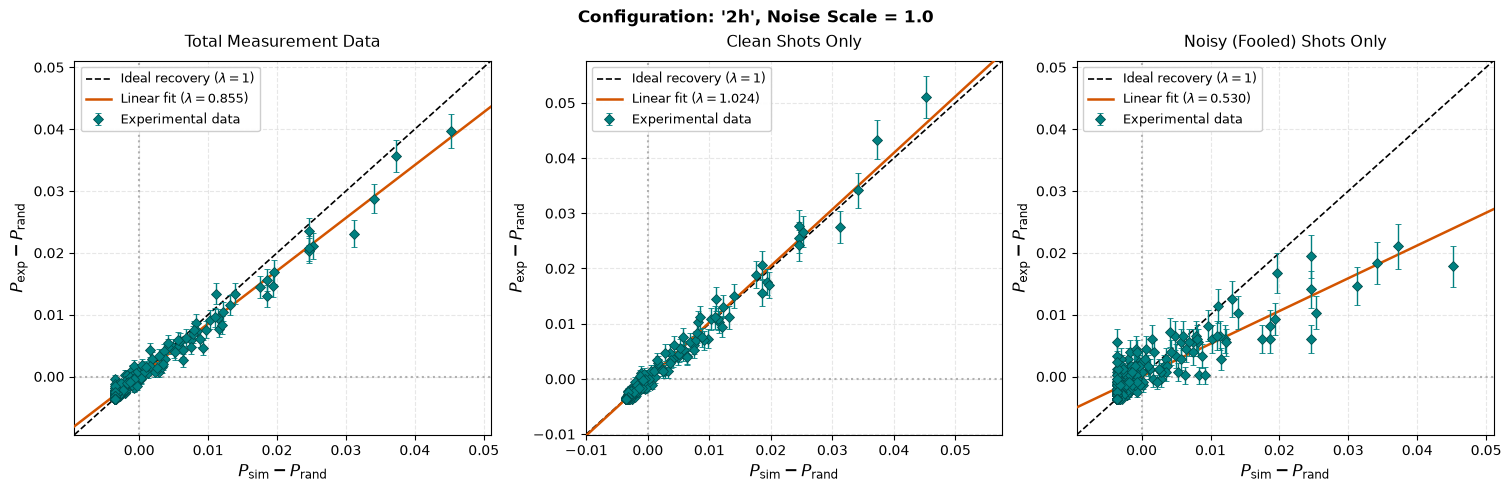

In [ ]:
# --- 1. Selection & Configuration ---
KEY = "2h"  # Options: "2h", "0h_long", "0h_short"
NOISE_SCALE = 1.



# --- 2. Load & Prepare Data ---
filename = file_dict[KEY]
dir_path = base_data_dir / filename
opt_data = load_something(filename, directory=dir_path)
symmetry_preset = symmetry_dict[KEY]

sim_data = run_base_quantum_simulation(
    opt_data,
    num_trajectories=128,
    num_measurements=100,
    noise_scale=NOISE_SCALE,
    include_rx=False,
)

# --- 3. Compute Metrics and Plot via For Loops ---
subpopulations = {
    "Total Measurement Data": "counts_total",
    "Clean Shots Only": "counts_clean",
    "Noisy (Fooled) Shots Only": "counts_fooled"
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), layout="constrained")

for ax, (title, count_key) in zip(axes, subpopulations.items()):
    # Compute metrics dynamically using the loop key
    metrics = compute_metrics(
        counts_input=sim_data[count_key],
        psi_tgt=sim_data["psi_tgt"],
        psi_result=sim_data["psi_ideal"],
        vList=sim_data["vList"],
        nodes_sorted=sim_data["nodes_sorted"],
        Ly=sim_data["dims"][0],
        Lx=sim_data["dims"][1],
        symmetry_preset=symmetry_preset,
        verbose=False
    )
    
    # Plot using the current axis
    plot_symmetry_delta_p_correlation(
        metrics,
        title=title,
        x_axis_mode="noiseless",
        show_fit_stats=True,
        ax=ax,
    )

fig.suptitle(
    f"Configuration: '{KEY}', Noise Scale = {NOISE_SCALE}",
    fontsize=12,
    weight="bold",
)

plt.show()

## Noise scaling

### generate data

In [ ]:
from tqdm.notebook import tqdm
# 1. Define the list of noise scales to simulate
noise_scales = [0., 0.2, 0.4, 0.6, 0.8, 0.9, 1., 1.1, 1.2, 1.3, 1.4, 1.5, 2., 3., 4.]

# 2. Simulation parameters
num_trajectories = 128
num_measurements = 400

KEY = "2h"  # Options: "2h", "0h_long", "0h_short"
filename = file_dict[KEY]
dir_path = base_data_dir / filename
opt_data = load_something(filename, directory=dir_path)
base_filename = filename


data_dir_name = 'test_noise_scaling'
#data_dir_name = 'noise_scaling' #replaces original data

# 3. Main execution loop
for ns in tqdm(noise_scales):
    # Format noise_scale to replace '.' with '-' (e.g., 0.2 -> "0-2", 1.5 -> "1-5")
    noise_str = f"{ns:.2f}".replace(".", "-")

    # Build unique filename base
    fname = f"{base_filename}_NT{num_trajectories}_NM_{num_measurements}_noise_{noise_str}"

    print(f"\n--- Running Simulation for noise_scale = {ns} ({fname}) ---")

    # Run simulation
    sim_result = run_base_quantum_simulation(
        opt_data,
        num_trajectories=num_trajectories,
        num_measurements=num_measurements,
        noise_scale=ns,
        include_rx=False,
    )
    os.makedirs(dir_path / data_dir_name, exist_ok=True)
    # Save dictionary as pkl using helper function
    save_something(
        data=sim_result, filename=fname, directory=dir_path / data_dir_name
    )

print("\nAll simulations completed and saved successfully.")

### Plotting

In [ ]:
import os
import glob
import numpy as np
import pandas as pd

def process_noise_sweep_results(
    dir_path,
    data_dir_name="noise_scaling",
    symmetry_preset="2h",
    x_axis_mode="noiseless",  # 'noiseless' or 'tgt'
    skip=[]
):
    """
    Loads saved simulation results,
    computes symmetry orbit metrics, and extracts key summary statistics:
      - noise_scale
      - survival_rate (passed post-selection fraction)
      - not_fooled_rate (clean fraction of post-selected shots)
      - unweighted_fit_slope (visibility lambda from unweighted polyfit)
    """
    data_dir = os.path.join(dir_path, data_dir_name)
    file_pattern = os.path.join(data_dir, "*.pkl")
    pkl_files = glob.glob(file_pattern)

    if not pkl_files:
        raise FileNotFoundError(f"No .pkl files found in directory: {data_dir}")

    results_summary = []

    for filepath in sorted(pkl_files):
        # 1. Load data
        sim_res = load_something(os.path.basename(filepath).replace(".pkl", ""), directory=data_dir)
        
        # 2. Extract metadata
        noise_scale = sim_res.get("noise_scale", None)
        # Fallback to parse noise_scale from filename if not explicitly stored in dict
        if noise_scale is None:
            filename = os.path.basename(filepath)
            noise_str = filename.split("noise_")[-1].replace(".pkl", "").replace("-", ".")
            noise_scale = float(noise_str)
        if noise_scale in skip:
            continue
        survival_rate = sim_res["survival_rate"]
        not_fooled_rate = sim_res["not_fooled_rate"]

        # 3. Compute orbit metrics using total post-selected counts
        metrics = compute_metrics(
            counts_input=sim_res["counts_total"],
            psi_tgt=sim_res["psi_tgt"],
            psi_result=sim_res["psi_ideal"],
            vList=sim_res["vList"],
            nodes_sorted=sim_res["nodes_sorted"],
            Ly=sim_res["dims"][0],
            Lx=sim_res["dims"][1],
            symmetry_preset=symmetry_preset,
        )

        # 4. Extract Delta P vectors
        delta_noisy = metrics["noisy_probs"] - metrics["y_random"]
        
        use_noiseless = x_axis_mode.lower() in ["noiseless", "ideal"]
        if use_noiseless:
            x_delta = metrics["ideal_probs"] - metrics["y_random"]
        else:
            x_delta = metrics["tgt_probs"] - metrics["y_random"]

        # 5. Compute UNWEIGHTED linear fit slope: y = a*x + b (more robust)
        # Force unweighted np.polyfit ignoring error bars
        fit_poly = np.polyfit(x_delta, delta_noisy, 1)
        unweighted_slope = fit_poly[0]
        intercept = fit_poly[1]

        # 6. Store record
        results_summary.append({
            "noise_scale": noise_scale,
            "survival_rate": survival_rate,
            "not_fooled_rate": not_fooled_rate,
            "unweighted_slope": unweighted_slope,
            "intercept": intercept,
            "filename": os.path.basename(filepath),
            "metrics": metrics
        })

    # Sort results sequentially by noise scale
    results_summary.sort(key=lambda x: x["noise_scale"])

    # Create a lightweight pandas DataFrame for easy inspection/plotting
    df_summary = pd.DataFrame([{
        "noise_scale": r["noise_scale"],
        "survival_rate": r["survival_rate"],
        "not_fooled_rate": r["not_fooled_rate"],
        "unweighted_slope": r["unweighted_slope"],
        "intercept": r["intercept"]
    } for r in results_summary])

    print("--- Noise Sweep Processing Complete ---")
    print(df_summary.to_string(index=False))

    return results_summary, df_summary


In [16]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection


def plot_slope_vs_survival(
    df_summary,
    exp_survival_rate=None,
    exp_unweighted_slope=None,
    exp_label="Experiment (Real Device)",
    output_path=None,
    cmap_name="viridis",
):
    """Plots unweighted slope vs. survival rate with a line and markers colored by

    the not_fooled_rate using a continuous colormap.

    Optional Parameters
    -------------------
    exp_survival_rate : float or None
        Survival rate (post-selection fraction) for the experimental data point.
    exp_unweighted_slope : float or None
        Unweighted visibility slope (lambda) for the experimental data point.
    exp_label : str
        Label for the experimental point in the plot legend.
    """
    # 1. Sort values by survival_rate for continuous line connection
    df_sorted = df_summary.sort_values(by="survival_rate").reset_index(
        drop=True
    )

    x = df_sorted["survival_rate"].values
    y = df_sorted["unweighted_slope"].values
    c_vals = df_sorted["not_fooled_rate"].values

    fig, ax = plt.subplots(figsize=(7.5, 5.5))

    # 2. Build multi-colored line segments via LineCollection
    points = np.array([x, y]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)

    segment_c = 0.5 * (c_vals[:-1] + c_vals[1:])

    lc = LineCollection(
        segments, cmap=cmap_name, norm=plt.Normalize(c_vals.min(), c_vals.max())
    )
    lc.set_array(segment_c)
    lc.set_linewidth(2.2)
    lc.set_zorder(1)
    ax.add_collection(lc)

    # 3. Scatter simulation points
    sc = ax.scatter(
        x,
        y,
        c=c_vals,
        cmap=cmap_name,
        s=60,
        edgecolor="black",
        linewidth=0.8,
        zorder=2,
        label="Simulated Noise Model",
    )

    # 4. Plot real experimental point (Red Point / Star) if passed
    if exp_survival_rate is not None and exp_unweighted_slope is not None:
        ax.scatter(
            exp_survival_rate,
            exp_unweighted_slope,
            color="#E74C3C",  # Vibrant red
            marker="*",  # Star marker (or 'o' for standard point)
            s=180,
            edgecolor="black",
            linewidth=1.0,
            zorder=5,
            label=exp_label,
        )

        # Annotate experimental point
        ax.annotate(
            f" {exp_label}",
            (exp_survival_rate, exp_unweighted_slope),
            fontsize=8.5,
            weight="bold",
            color="#B03A2E",
            va="center",
        )

    # 5. Colorbar setup
    cbar = fig.colorbar(sc, ax=ax, pad=0.03)
    cbar.set_label("Not-Fooled Rate (Clean / Post-Selected)", fontsize=10)

    # 6. Formatting & Annotations
    ax.set_xlabel("Survival Rate (Post-Selection Fraction)", fontsize=11)
    ax.set_ylabel(r"Unweighted Visibility Slope ($\lambda$)", fontsize=11)
    ax.set_title(
        r"Signal Visibility $\lambda$ vs. Survival Rate",
        fontsize=12,
        pad=10,
        weight="bold",
    )

    ax.grid(True, linestyle="--", alpha=0.4)

    # Annotate simulation points with noise_scale
    for idx, row in df_sorted.iterrows():
        ax.annotate(
            f" scale={row['noise_scale']:.1f}",
            (row["survival_rate"], row["unweighted_slope"]),
            fontsize=8,
            alpha=0.7,
            va="center",
        )

    # Adjust axis limits to fit both simulation and experimental point
    all_x = x.tolist()
    all_y = y.tolist()
    if exp_survival_rate is not None:
        all_x.append(exp_survival_rate)
    if exp_unweighted_slope is not None:
        all_y.append(exp_unweighted_slope)

    pad_x = 0.08 * (max(all_x) - min(all_x)) if len(all_x) > 1 else 0.05
    pad_y = 0.08 * (max(all_y) - min(all_y)) if len(all_y) > 1 else 0.05

    ax.set_xlim(min(all_x) - pad_x, max(all_x) + pad_x)
    ax.set_ylim(min(all_y) - pad_y, max(all_y) + pad_y)

    ax.legend(fontsize=9, loc="best", framealpha=0.9)

    plt.tight_layout()

    if output_path:
        plt.savefig(output_path, dpi=300, bbox_inches="tight")
        print(f"Plot saved to: {output_path}")
    else:
        plt.show()


--- Post-Selection Analysis ---
Evaluated across 1 layout(s)/result(s) separately.
Target Particle Count: 3
Total Shots Attempted: 81920
Total Shots Passed Post-Selection: 81920
Fraction of valid states: 1.0000 (100.00%)
--------------------------------
--- Post-Selection Analysis ---
Evaluated across 1 layout(s)/result(s) separately.
Target Particle Count: 3
Total Shots Attempted: 67442
Total Shots Passed Post-Selection: 67442
Fraction of valid states: 1.0000 (100.00%)
--------------------------------
--- Post-Selection Analysis ---
Evaluated across 1 layout(s)/result(s) separately.
Target Particle Count: 3
Total Shots Attempted: 57293
Total Shots Passed Post-Selection: 57293
Fraction of valid states: 1.0000 (100.00%)
--------------------------------
--- Post-Selection Analysis ---
Evaluated across 1 layout(s)/result(s) separately.
Target Particle Count: 3
Total Shots Attempted: 49529
Total Shots Passed Post-Selection: 49529
Fraction of valid states: 1.0000 (100.00%)
-----------------

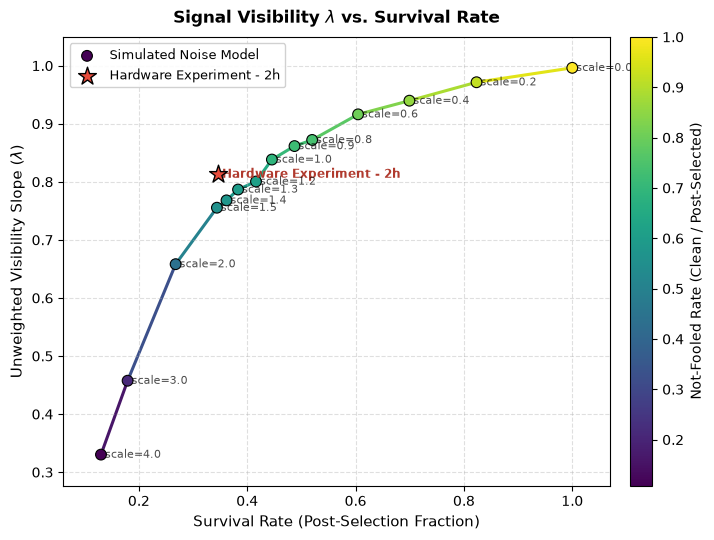

In [ ]:

KEY = "2h"  # Options: "2h", "0h_long", "0h_short"
filename = file_dict[KEY]
dir_path = base_data_dir / filename

# --- Usage Example ---
results_summary, df_summary = process_noise_sweep_results(
    dir_path=dir_path,
    symmetry_preset=symmetry_dict[KEY],
    x_axis_mode="noiseless"
)

exp_survival_rate, exp_unweighted_slope = experiment_dict[KEY]
# --- Usage Example ---
plot_slope_vs_survival(
    df_summary,
    exp_survival_rate=exp_survival_rate,  # experimental survival rate
    exp_unweighted_slope=exp_unweighted_slope,  # experimental fit slope
    exp_label=f"Hardware Experiment - {KEY}",
)

### Combined plot

In [27]:
from matplotlib.collections import LineCollection
import matplotlib.pyplot as plt
import numpy as np


def plot_two_panel_slope_vs_survival(
    df_summary1,
    df_summary2,
    exp_data1=None,  # Tuple: (exp_survival_rate, exp_unweighted_slope)
    exp_data2=None,  # Tuple: (exp_survival_rate, exp_unweighted_slope)
    output_path=None,
    cmap_name="viridis",
    # Target annotation subsets per panel
    annotate_scales_panel1={0.0, 0.2, 0.6, 1.0, 1.2, 1.5, 2.0, 3.0, 4.0},
    annotate_scales_panel2={0.0, 0.2, 0.6, 0.9, 1.2, 2.0, 3.0, 4.0},
    # Configurable font size for annotations
    annotation_fontsize=8.0,
    # Manual offsets per panel relative to (0,0) = marker center
    offsets_panel1=None,  # Dict: {c_val: (dx_pt, dy_pt)}
    offsets_panel2=None,  # Dict: {c_val: (dx_pt, dy_pt)}
):
    """Generates a publication-ready 2-panel plot with pure manual label placement,

    framed text boxes, and pointer connections to the top-left of each text box.
    """
    # Default baseline offset (dx, dy) in display points
    default_offset = (12, -12)

    # Pre-configured default offset dictionaries if none provided
    if offsets_panel1 is None:
        offsets_panel1 = {
            0.0: (-26, -8),  # Top-right edge: shift left to stay inside frame
            0.2: (-18, 12),  # Shift top-left
            0.6: (12, 10),  # Shift top-right
            1.0: (12, 2),  # Shift right
            1.2: (12, -6),  # Shift bottom-right
            1.5: (12, -12),
            2.0: (12, -12),
            3.0: (12, -12),
            4.0: (12, -12),
        }

    if offsets_panel2 is None:
        offsets_panel2 = {
            0.0: (-26, -8),  # Top-right edge
            0.2: (-18, 12),
            0.6: (12, 10),
            0.9: (14, 2),  # Tailored for panel (b)
            1.2: (12, -6),
            2.0: (12, -12),
            3.0: (12, -12),
            4.0: (12, -12),
        }

    # 1. Standardize color limits starting strictly at 0.0
    vmin, vmax = 0.0, 1.0
    norm = plt.Normalize(vmin, vmax)

    # 2. Create subplots sharing Y-axis
    fig, (ax1, ax2) = plt.subplots(
        1, 2, figsize=(7.2, 3.8), sharey=True, gridspec_kw={"wspace": 0.08}
    )

    panels = [
        (
            ax1,
            df_summary1,
            exp_data1,
            annotate_scales_panel1,
            offsets_panel1,
            "(a)",
        ),
        (
            ax2,
            df_summary2,
            exp_data2,
            annotate_scales_panel2,
            offsets_panel2,
            "(b)",
        ),
    ]

    sc_for_cbar = None

    for (
        ax,
        df_summary,
        exp_data,
        annotate_scales,
        panel_offsets,
        panel_label,
    ) in panels:
        df_sorted = df_summary.sort_values(by="survival_rate").reset_index(
            drop=True
        )

        x = df_sorted["survival_rate"].values
        y = df_sorted["unweighted_slope"].values
        c_vals = df_sorted["not_fooled_rate"].values

        # Line collection
        points = np.array([x, y]).T.reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        segment_c = 0.5 * (c_vals[:-1] + c_vals[1:])

        lc = LineCollection(segments, cmap=cmap_name, norm=norm)
        lc.set_array(segment_c)
        lc.set_linewidth(1.8)
        lc.set_zorder(1)
        ax.add_collection(lc)

        # Simulation scatter points
        sc = ax.scatter(
            x,
            y,
            c=c_vals,
            cmap=cmap_name,
            norm=norm,
            s=50,
            edgecolor="black",
            linewidth=0.7,
            zorder=3,
            label="Simulation",
        )
        sc_for_cbar = sc

        # Experimental point (Red Diamond)
        if exp_data is not None:
            exp_rate, exp_slope = exp_data
            if exp_rate is not None and exp_slope is not None:
                ax.scatter(
                    exp_rate,
                    exp_slope,
                    color="#D62728",
                    marker="D",
                    s=55,
                    edgecolor="black",
                    linewidth=0.8,
                    zorder=5,
                    label="Experiment",
                )

        # --- MANUAL ANNOTATION LOOP ---
        custom_dict = panel_offsets if panel_offsets is not None else {}

        for idx, row in df_sorted.iterrows():
            c_val = round(row["noise_scale"], 2)

            # Check if this scale is enabled for this panel
            if annotate_scales is not None and c_val not in annotate_scales:
                continue

            # Get custom offset or fallback to default
            dx, dy = custom_dict.get(c_val, default_offset)

            # Connecting from top-left corner of the text box (ha="left", va="top")
            ax.annotate(
                f"$c={c_val:.1f}$",
                xy=(row["survival_rate"], row["unweighted_slope"]),
                xytext=(dx, dy),
                textcoords="offset points",
                fontsize=annotation_fontsize,
                color="black",
                ha="left",  # Anchor point is left side of text box
                va="top",  # Anchor point is top side of text box
                bbox=dict(
                    boxstyle="round,pad=0.2",
                    fc="white",
                    ec="gray",
                    lw=0.4,
                    alpha=0.85,
                ),
                arrowprops=dict(
                    arrowstyle="-",
                    color="gray",
                    lw=0.5,
                    shrinkA=0,  # Touches text box boundary cleanly
                    shrinkB=3,  # Slight clearance near scatter marker
                ),
                zorder=4,
            )

        # Panel Label
        ax.text(
            0.04,
            0.92,
            panel_label,
            transform=ax.transAxes,
            fontsize=11,
            fontweight="bold",
            va="top",
        )

        # Axis formatting
        ax.set_xlabel("Post-selection rate", fontsize=11)
        ax.grid(True, linestyle="--", alpha=0.4)

        # Axis Padding
        all_x = x.tolist()
        if exp_data and exp_data[0] is not None:
            all_x.append(exp_data[0])

        pad_x = 0.12 * (max(all_x) - min(all_x)) if len(all_x) > 1 else 0.05
        ax.set_xlim(min(all_x) - pad_x, max(all_x) + pad_x * 1.35)

        # Legend
        ax.legend(
            fontsize=10,
            loc="lower right",
            frameon=True,
            facecolor="white",
            framealpha=0.9,
            edgecolor="gray",
        )

    # Set Y-label on left panel
    ax1.set_ylabel(r"Attenuation factor $\lambda$", fontsize=11)

    # 3. Top Colorbar starting strictly at 0.0
    pos1 = ax1.get_position()
    pos2 = ax2.get_position()
    cax = fig.add_axes([pos1.x0, pos1.y1 + 0.03, pos2.x1 - pos1.x0, 0.035])

    cbar = fig.colorbar(
        sc_for_cbar, cax=cax, orientation="horizontal", ticklocation="top"
    )
    cbar.set_label(r"Error-free fraction $1-p_{\mathrm{noise}}$", fontsize=11, labelpad=6)
    cbar.ax.tick_params(labelsize=10)

    if output_path:
        plt.savefig(output_path, dpi=300, bbox_inches="tight")
        print(f"Plot saved to: {output_path}")
    else:
        plt.show()

In [26]:
KEY = "2h"  # Options: "2h", "0h_long", "0h_short"
filename = file_dict[KEY]
dir_path = base_data_dir / filename
# 1. Process both noise sweeps
_, df_summary_2h = process_noise_sweep_results(
    dir_path=dir_path,
    symmetry_preset=symmetry_dict[KEY],
    x_axis_mode="noiseless"
)
KEY = "0h_long"  # Options: "2h", "0h_long", "0h_short"
filename = file_dict[KEY]
dir_path = base_data_dir / filename
_, df_summary_0h = process_noise_sweep_results(
    dir_path=dir_path,
    symmetry_preset=symmetry_dict[KEY],
    x_axis_mode="noiseless"
)


--- Post-Selection Analysis ---
Evaluated across 1 layout(s)/result(s) separately.
Target Particle Count: 3
Total Shots Attempted: 81920
Total Shots Passed Post-Selection: 81920
Fraction of valid states: 1.0000 (100.00%)
--------------------------------
--- Post-Selection Analysis ---
Evaluated across 1 layout(s)/result(s) separately.
Target Particle Count: 3
Total Shots Attempted: 67442
Total Shots Passed Post-Selection: 67442
Fraction of valid states: 1.0000 (100.00%)
--------------------------------
--- Post-Selection Analysis ---
Evaluated across 1 layout(s)/result(s) separately.
Target Particle Count: 3
Total Shots Attempted: 57293
Total Shots Passed Post-Selection: 57293
Fraction of valid states: 1.0000 (100.00%)
--------------------------------
--- Post-Selection Analysis ---
Evaluated across 1 layout(s)/result(s) separately.
Target Particle Count: 3
Total Shots Attempted: 49529
Total Shots Passed Post-Selection: 49529
Fraction of valid states: 1.0000 (100.00%)
-----------------

Plot saved to: ../figs/slope_vs_survival_twopanel_v2.pdf


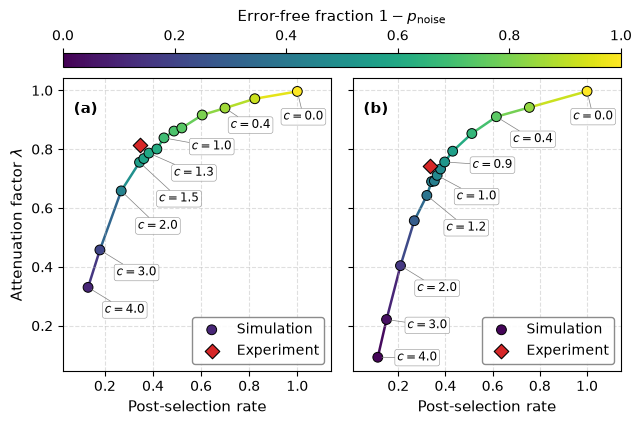

In [29]:

# Manual (dx, dy) offsets relative to (0,0) = marker center
# Keeping (12, -12) as default where no collision occurs

offsets_2h = {
    0.0: (-10, -14),  # Shift left/down to fit inside plot corner
    0.4: (4, -8),  # Above-right of curve
    1.0: (20, -2),  # Shifted up-right to clear 1.2
    1.3: (18, -10),  # Extended right horizontally
    1.5: (14, -22),  # Shifted down-right to clear 1.2
    2.0: (12, -21),  # Default
    3.0: (12, -12),  # Default
    4.0: (12, -12),  # Default
}

offsets_0h = {
    0.0: (-10, -14),  # Shift left/down to fit inside plot corner
    0.6: (4, -8),  # Above-right of curve
    0.9: (20, 2),  # Middle-right
    1.0: (14, -11),  # Middle-right
    1.2: (14, -19),  # Shifted down-right to clear 0.9
    2.0: (12, -12),  # Default
    3.0: (15, 0),  # Default
    4.0: (14, 4),  # Shifted up-right so it doesn't clip the bottom x-axis frame
}

# 1. Target annotation subsets per panel
annotate_2h = {0.0, 0.4, 1.0, 1.3, 1.5, 2.0, 3.0, 4.0}
annotate_0h = {0.0, 0.4, 0.9, 1.0, 1.2, 2.0, 3.0, 4.0}

exp_points = {
    "2h": (0.346, 0.813),
    "0h long": (0.333, 0.742),
}

plot_two_panel_slope_vs_survival(
    df_summary1=df_summary_2h,
    df_summary2=df_summary_0h,
    exp_data1=exp_points["2h"],
    exp_data2=exp_points["0h long"],
    annotate_scales_panel1=annotate_2h,
    annotate_scales_panel2=annotate_0h,
    offsets_panel1=offsets_2h,
    offsets_panel2=offsets_0h,
    output_path="../figs/slope_vs_survival_twopanel_v2.pdf",
    annotation_fontsize=8.5
)